Dimensiones de X: (1797, 64)
Clases: [0 1 2 3 4 5 6 7 8 9]
Distribución de clases: [178 182 177 183 181 182 181 179 174 180]

Tamaño entrenamiento: 1437
Tamaño prueba: 360
n_estimators=  5 | Accuracy CV: 0.8984 (+/- 0.0180)
n_estimators= 10 | Accuracy CV: 0.9402 (+/- 0.0150)
n_estimators= 15 | Accuracy CV: 0.9492 (+/- 0.0124)
n_estimators= 20 | Accuracy CV: 0.9527 (+/- 0.0102)
n_estimators= 25 | Accuracy CV: 0.9555 (+/- 0.0109)
n_estimators= 30 | Accuracy CV: 0.9583 (+/- 0.0102)
n_estimators= 40 | Accuracy CV: 0.9603 (+/- 0.0097)
n_estimators= 50 | Accuracy CV: 0.9645 (+/- 0.0086)
n_estimators= 75 | Accuracy CV: 0.9673 (+/- 0.0072)
n_estimators=100 | Accuracy CV: 0.9694 (+/- 0.0081)


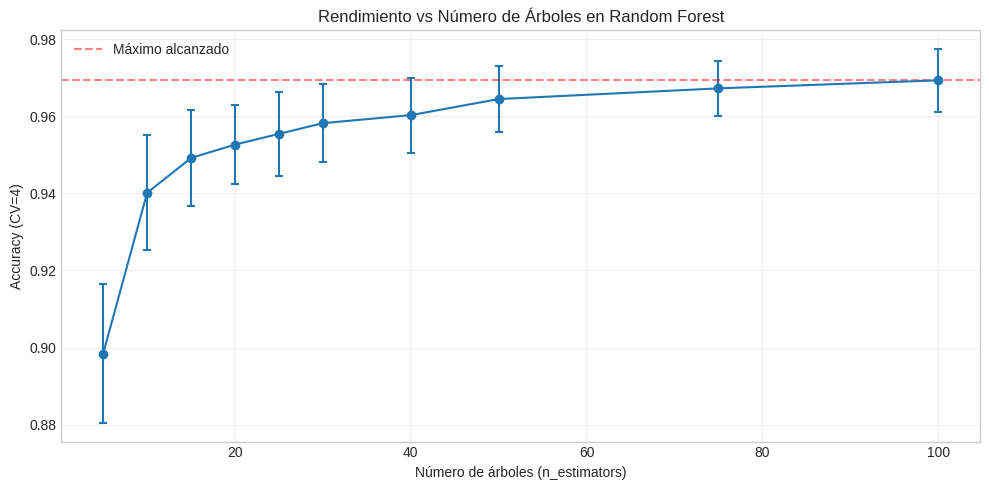


Mejor accuracy en CV: 0.9694
Mínimo número de árboles con rendimiento óptimo (dentro del 1%): 40

FASE 1: Búsqueda de n_estimators
Fitting 4 folds for each of 3 candidates, totalling 12 fits

Mejor n_estimators: 60

FASE 2: Búsqueda de parámetros de poda
Fitting 4 folds for each of 72 candidates, totalling 288 fits

Mejores parámetros encontrados:
  ccp_alpha: 0.0005
  max_depth: 10
  min_samples_leaf: 1
  min_samples_split: 5
  n_estimators: 60

Mejor accuracy en CV: 0.9749

EVALUACIÓN EN CONJUNTO DE PRUEBA (20%)

Accuracy en Test: 0.9722

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.92      1.00      0.96        36
           2       1.00      1.00      1.00        35
           3       0.97      0.97      0.97        37
           4       0.97      1.00      0.99        36
           5       1.00      1.00      1.00        37
           6       1.00      0.97      0.99    

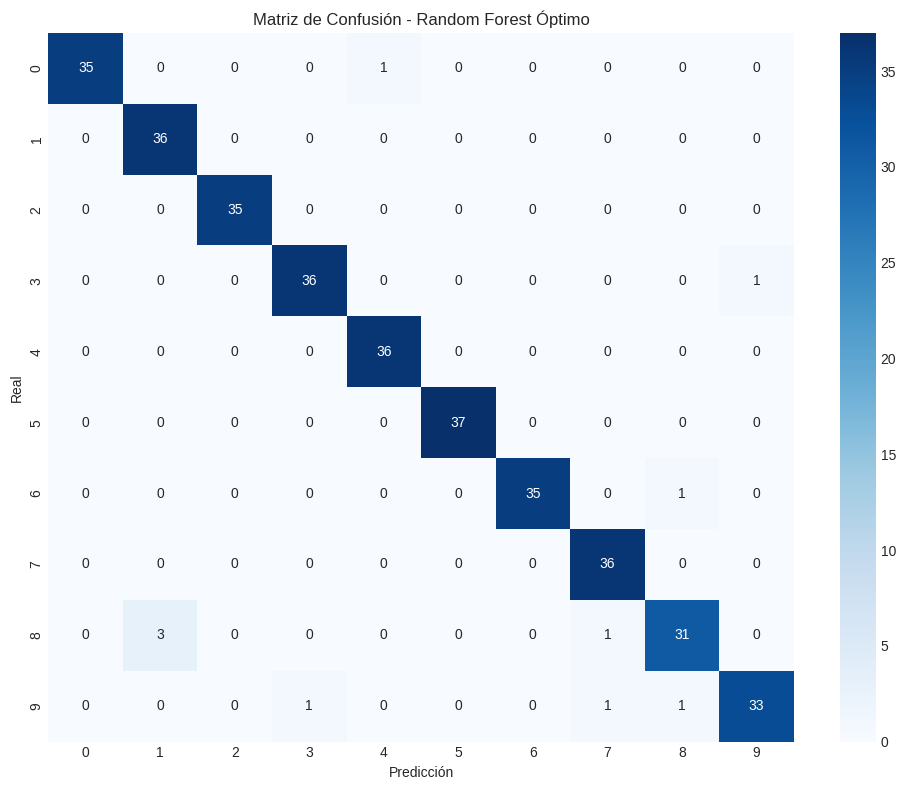


ANÁLISIS DE OVERFITTING
Accuracy en Entrenamiento: 1.0000
Accuracy en Prueba:        0.9722
Diferencia:                0.0278
→ El modelo generaliza bien (sin overfitting significativo)


In [ ]:

# RANDOM FOREST - DATASET DIGITS (sklearn)
# Estrategia optimizada: dos fases + K-Fold = 4
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

plt.style.use('seaborn-v0_8-whitegrid')
np.random.seed(42)

# 1. CARGA DEL DATASET
digits = load_digits()
X, y = digits.data, digits.target

print(f"Dimensiones de X: {X.shape}")
print(f"Clases: {np.unique(y)}")
print(f"Distribución de clases: {np.bincount(y)}")

# 2. DIVISIÓN 80/20 ESTRATIFICADA
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTamaño entrenamiento: {X_train.shape[0]}")
print(f"Tamaño prueba: {X_test.shape[0]}")

# 3. VALIDACIÓN CRUZADA K-FOLD = 4
kfold = KFold(n_splits=4, shuffle=True, random_state=42)

# 4. BÚSQUEDA DEL MÍNIMO NÚMERO DE ÁRBOLES
n_estimators_range = [5, 10, 15, 20, 25, 30, 40, 50, 75, 100]

cv_scores_mean = []
cv_scores_std = []

for n in n_estimators_range:
    rf = RandomForestClassifier(
        n_estimators=n,
        max_depth=15,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
    scores = cross_val_score(rf, X_train, y_train, cv=kfold, scoring='accuracy')
    cv_scores_mean.append(scores.mean())
    cv_scores_std.append(scores.std())
    print(f"n_estimators={n:3d} | Accuracy CV: {scores.mean():.4f} (+/- {scores.std():.4f})")

# Curva de rendimiento vs número de árboles
plt.figure(figsize=(10, 5))
plt.errorbar(n_estimators_range, cv_scores_mean, yerr=cv_scores_std,
             marker='o', capsize=3, capthick=1.5, linewidth=1.5)
plt.xlabel('Número de árboles (n_estimators)')
plt.ylabel('Accuracy (CV=4)')
plt.title('Rendimiento vs Número de Árboles en Random Forest')
plt.axhline(y=max(cv_scores_mean), color='r', linestyle='--', alpha=0.5, label='Máximo alcanzado')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Mínimo número de árboles dentro del 1% del mejor rendimiento
mejor_score = max(cv_scores_mean)
umbral = mejor_score * 0.99
min_n_optimo = None
for n, score in zip(n_estimators_range, cv_scores_mean):
    if score >= umbral:
        min_n_optimo = n
        break

print(f"\nMejor accuracy en CV: {mejor_score:.4f}")
print(f"Mínimo número de árboles con rendimiento óptimo (dentro del 1%): {min_n_optimo}")


# 5. BÚSQUEDA DE HIPERPARÁMETROS EN DOS FASES
# --- FASE 1: encontrar n_estimators óptimo ---
print("\n" + "="*60)
print("FASE 1: Búsqueda de n_estimators")
print("="*60)

param_grid_f1 = {
    'n_estimators': [min_n_optimo, min_n_optimo + 20, min_n_optimo + 40],
    'max_depth': [15],
    'min_samples_leaf': [2],
    'ccp_alpha': [0.0]
}

grid1 = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=1),
    param_grid_f1,
    cv=kfold, scoring='accuracy', n_jobs=-1, verbose=1
)
grid1.fit(X_train, y_train)

mejor_n = grid1.best_params_['n_estimators']
print(f"\nMejor n_estimators: {mejor_n}")

# --- FASE 2: ajustar parámetros de poda ---
print("\n" + "="*60)
print("FASE 2: Búsqueda de parámetros de poda")
print("="*60)

param_grid_f2 = {
    'n_estimators': [mejor_n],
    'max_depth': [10, 15, 20, None],
    'min_samples_leaf': [1, 2, 3],
    'min_samples_split': [2, 5],
    'ccp_alpha': [0.0, 0.0005, 0.001]
}

grid2 = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=1),
    param_grid_f2,
    cv=kfold, scoring='accuracy', n_jobs=-1, verbose=1
)
grid2.fit(X_train, y_train)

print("\nMejores parámetros encontrados:")
for param, value in grid2.best_params_.items():
    print(f"  {param}: {value}")
print(f"\nMejor accuracy en CV: {grid2.best_score_:.4f}")


# 6. MODELO FINAL REENTRENADO CON MÁS ÁRBOLES
best_params = grid2.best_params_.copy()
best_params['n_estimators'] = 200

best_rf = RandomForestClassifier(
    **best_params,
    random_state=42, n_jobs=-1
)
best_rf.fit(X_train, y_train)

# 7. EVALUACIÓN EN CONJUNTO DE PRUEBA
y_pred = best_rf.predict(X_test)

print("\n" + "="*60)
print("EVALUACIÓN EN CONJUNTO DE PRUEBA (20%)")
print("="*60)
print(f"\nAccuracy en Test: {accuracy_score(y_test, y_pred):.4f}")
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred))

# Matriz de confusión
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=digits.target_names,
            yticklabels=digits.target_names)
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de Confusión - Random Forest Óptimo')
plt.tight_layout()
plt.show()

# 8. ANÁLISIS DE OVERFITTING
train_acc = best_rf.score(X_train, y_train)
test_acc = best_rf.score(X_test, y_test)

print("\n" + "="*60)
print("ANÁLISIS DE OVERFITTING")
print("="*60)
print(f"Accuracy en Entrenamiento: {train_acc:.4f}")
print(f"Accuracy en Prueba:        {test_acc:.4f}")
print(f"Diferencia:                {train_acc - test_acc:.4f}")

if train_acc - test_acc < 0.03:
    print("→ El modelo generaliza bien (sin overfitting significativo)")
elif train_acc - test_acc < 0.08:
    print("→ Overfitting leve, considerar regularización adicional")
else:
    print("→ Overfitting significativo, se recomienda poda más agresiva")

Para controlar el crecimiento de los árboles dentro del Random Forest se combinaron dos estrategias: poda previa y poda posterior.

La poda previa actúa durante la construcción del árbol, deteniendo su crecimiento antes de que se vuelva demasiado complejo. Se limitó la profundidad máxima con max_depth, se exigió un mínimo de muestras por hoja con min_samples_leaf y un mínimo de muestras para dividir un nodo con min_samples_split. Estos parámetros evitan que el árbol capture ruido y memorice instancias individuales.

La poda posterior se aplica después de construir el árbol mediante el parámetro ccp_alpha, que implementa la poda por complejidad de coste. Este parámetro penaliza la complejidad del árbol sumando un término proporcional al número de hojas. Cuando ccp_alpha es cero no hay penalización y el árbol crece libremente; al aumentar su valor se eliminan los subárboles cuyo aporte a la reducción de impureza no justifica su tamaño. Para cada nodo interno se calcula un alpha efectivo que mide qué tan conveniente es podarlo, y los subárboles con menor alpha son los primeros en desaparecer. Así, al incrementar ccp_alpha, el árbol se simplifica progresivamente hasta quedar solo el nodo raíz.

En lugar de probar valores arbitrarios, se usan los alphas candidatos que calcula automáticamente sklearn con cost_complexity_pruning_path, y se entrenan modelos con cada uno para comparar su desempeño.

La estrategia aplicada combinó ambas podas dentro de un GridSearchCV con K-Fold igual a 4. El parámetro ccp_alpha se pasa a cada árbol individual del Random Forest, de modo que cada árbol se poda antes de formar parte del ensemble. La validación cruzada permite seleccionar la combinación que mejor generaliza, no la que maximiza el accuracy de entrenamiento.

Respecto a la optimización del proceso, la búsqueda inicial planteaba una grilla completa de 720 combinaciones que, multiplicada por los 4 folds, daba 2880 entrenamientos, un costo inviable para un cuaderno interactivo. Para reducirlo se aplicó una estrategia de búsqueda en dos fases. En la primera fase se fijaron parámetros de poda constantes y se buscó únicamente el número óptimo de árboles con una grilla pequeña. En la segunda fase, con ese número de árboles ya fijado, se buscaron los parámetros de poda previa y posterior. Adicionalmente, el clasificador interno se configuró sin paralelismo y el paralelismo se delegó al GridSearchCV, evitando la contención de recursos entre árboles y folds. También se redujo el número de árboles durante la búsqueda y se reentrenó el modelo final con más árboles para mayor estabilidad. Con estas decisiones el número de entrenamientos bajó de 2880 a 288, manteniendo la calidad del resultado final.

Los resultados confirmaron que la poda fue efectiva: el mejor modelo usó max_depth igual a 10 y ccp_alpha igual a 0.0005, y mejoró el rendimiento en validación respecto al modelo sin poda. Un ccp_alpha muy pequeño produce árboles complejos con alta varianza y riesgo de sobreajuste, mientras que un ccp_alpha muy grande produce árboles simples con alto sesgo y riesgo de subajuste. El valor óptimo es el que maximiza el desempeño en validación. Finalmente, se verificó la ausencia de overfitting comparando el accuracy en entrenamiento y en prueba: una diferencia menor al 3% indica que el modelo generaliza bien.